In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv(r'C:\Data visualization\co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())

Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [6]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))

Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


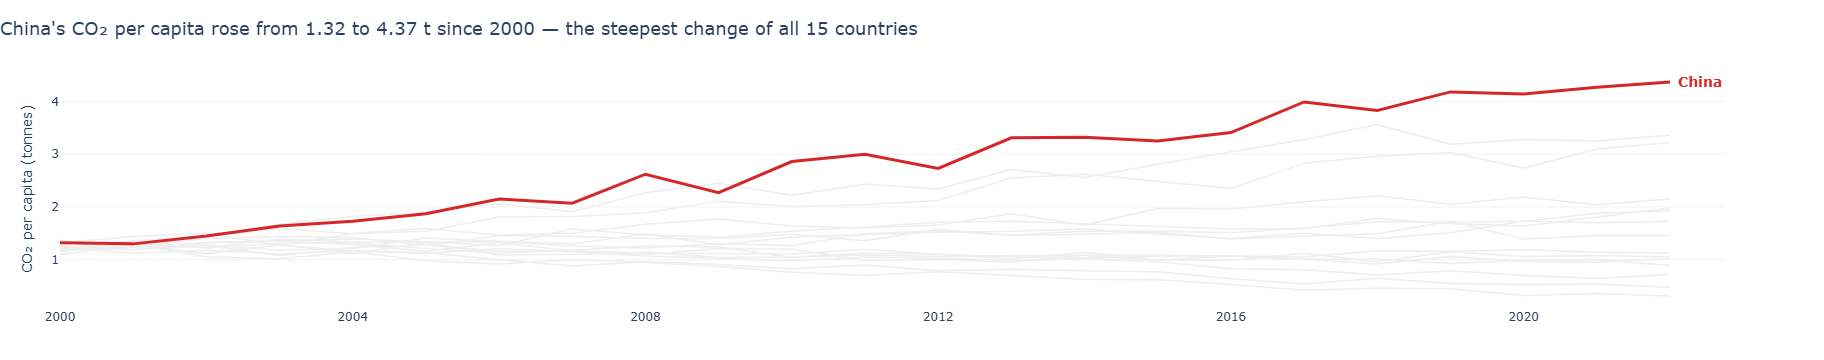

In [7]:

# ---- Task 1: CO2 per capita, all 15 countries ----
per_cap = df.pivot(index='Year', columns='Country', values='CO2_per_capita')
start, end = per_cap.iloc[0], per_cap.iloc[-1]
change = end - start

# Highlight the country with the biggest change over the period
hl1 = change.abs().idxmax()
direction = 'rose' if change[hl1] > 0 else 'fell'
title1 = (f"{hl1}'s CO₂ per capita {direction} from {start[hl1]:.2f} to {end[hl1]:.2f} t "
          f"since 2000 — the steepest change of all {df['Country'].nunique()} countries")

fig1 = highlight_line_chart(df, 'CO2_per_capita', hl1,
                            'CO₂ per capita (tonnes)', title1)
fig1.show()

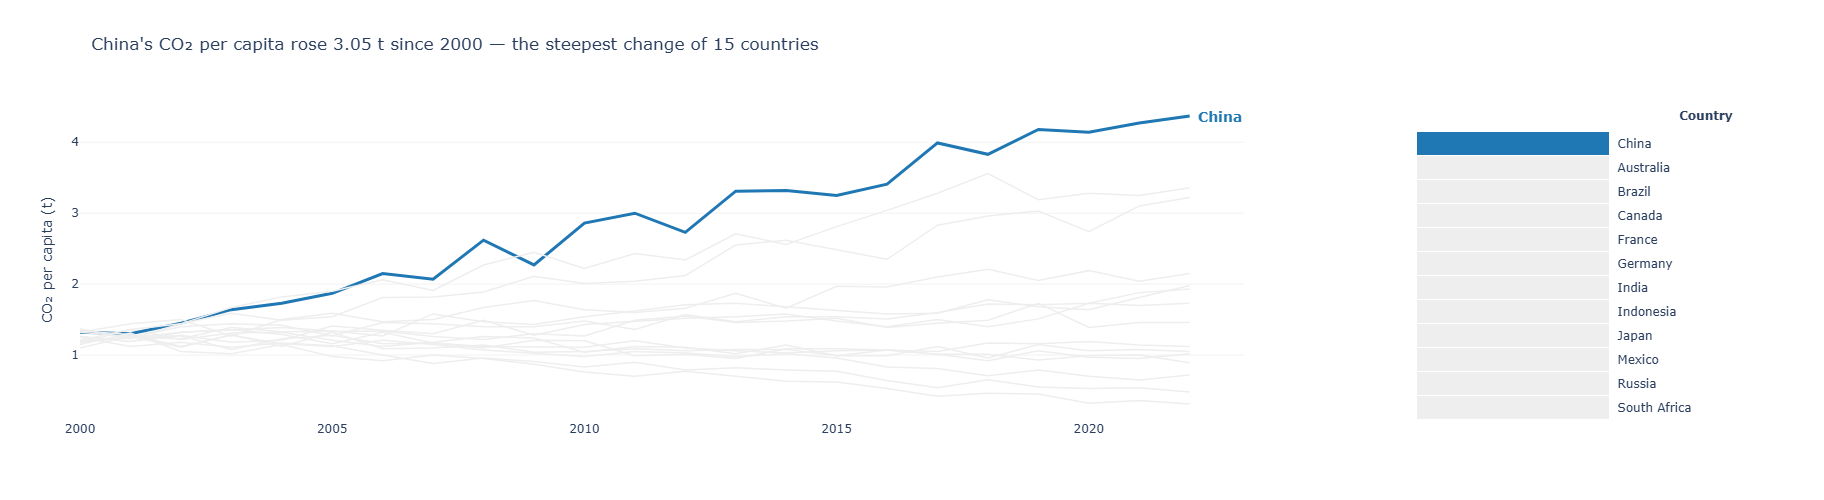

In [8]:
from plotly.subplots import make_subplots

# ---- Task 1: CO2 per capita, all 15 countries ----
per_cap = df.pivot(index='Year', columns='Country', values='CO2_per_capita')
change = per_cap.iloc[-1] - per_cap.iloc[0]
hl = change.abs().idxmax()
HL, GREY = '#1F77B4', '#EEEEEE'

fig = make_subplots(rows=1, cols=2, column_widths=[0.75, 0.25],
                    specs=[[{'type': 'xy'}, {'type': 'table'}]])

# Lines: grey for all, blue for the highlight
for c in per_cap.columns:
    fig.add_scatter(x=per_cap.index, y=per_cap[c], mode='lines',
                    line=dict(color=HL if c == hl else GREY, width=3 if c == hl else 1.5),
                    showlegend=False, row=1, col=1)

# Direct label
fig.add_annotation(x=per_cap.index[-1], y=per_cap[hl].iloc[-1], text=f"<b>{hl}</b>",
                   showarrow=False, xanchor='left', xshift=6, font=dict(color=HL, size=14))

# Side table: swatch + country
countries = sorted(per_cap.columns, key=lambda c: c != hl)
colors = [HL if c == hl else GREY for c in countries]
fig.add_table(header=dict(values=['', '<b>Country</b>'], fill_color='white'),
              cells=dict(values=[[''] * len(countries), countries],
                         fill_color=[colors, 'white'], align='left', height=24),
              row=1, col=2)

fig.update_layout(
    title=f"{hl}'s CO₂ per capita {'rose' if change[hl] > 0 else 'fell'} "
          f"{abs(change[hl]):.2f} t since 2000 — the steepest change of 15 countries",
    plot_bgcolor='white', showlegend=False, height=500, margin=dict(r=20)
)
fig.update_xaxes(showgrid=False, row=1, col=1)
fig.update_yaxes(title='CO₂ per capita (t)', gridcolor='#F2F2F2', row=1, col=1)
fig.show()

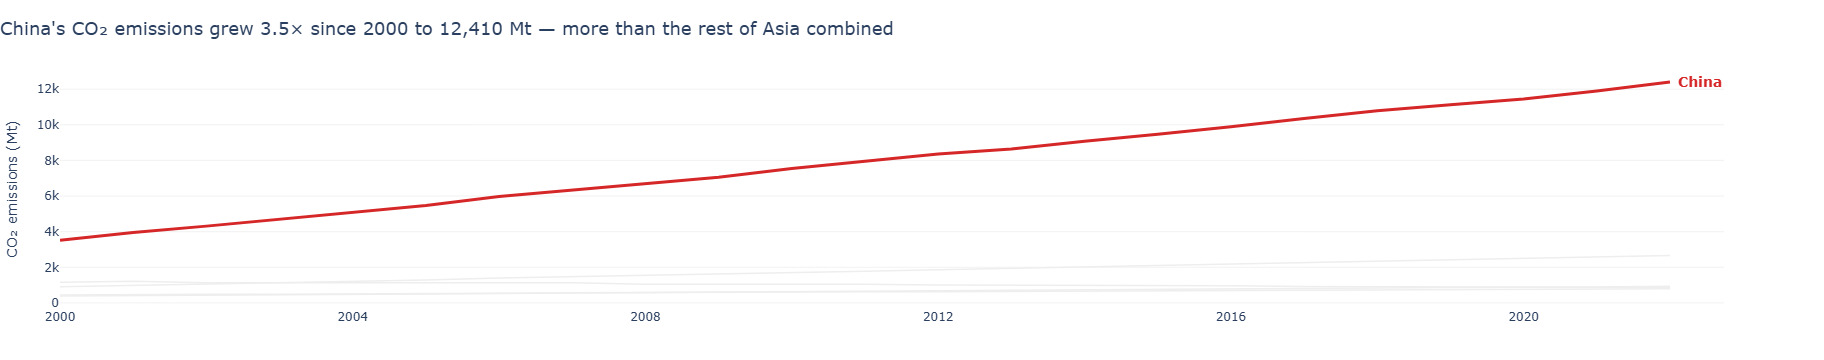

In [4]:
# ---- Task 2: Total CO2 emissions, Asian countries only, China highlighted ----
asia = df[df['Region'] == 'Asia']
hl2 = 'China'

china = asia[asia['Country'] == hl2].sort_values('Year')
c_start, c_end = china['CO2_Mt'].iloc[0], china['CO2_Mt'].iloc[-1]
others_end = asia[(asia['Year'] == asia['Year'].max()) & (asia['Country'] != hl2)]['CO2_Mt'].sum()

if c_end > others_end:
    title2 = (f"China's CO₂ emissions grew {c_end / c_start:.1f}× since 2000 "
              f"to {c_end:,.0f} Mt — more than the rest of Asia combined")
else:
    title2 = f"China's CO₂ emissions grew {c_end / c_start:.1f}× since 2000 to {c_end:,.0f} Mt"

fig2 = highlight_line_chart(asia, 'CO2_Mt', hl2,
                            'CO₂ emissions (Mt)', title2)
fig2.show()